# Modeling Human Activity States with a Hidden Markov Model

This notebook takes the raw accelerometer and gyroscope recordings in `data/raw/`, harmonises them to one sampling rate, cuts them into windows, extracts time- and frequency-domain features, and fits a Gaussian-emission HMM written from scratch in numpy (forward–backward, Baum–Welch, Viterbi). It then decodes the unseen test recordings and produces every table and figure the report needs.

**How to run.** Put the phone exports in `data/raw/<member>/` following the naming rules in the README, fill in `data/segment_labels.csv` for any mixed-activity recording, then *Run All*. Figures go to `figures/`, tables to `results/`, and one cleaned CSV per recording to `data/clean/`.

Sections follow the assignment: 1 data collection and pre-processing, 2 feature extraction, 3 model components, 4 implementation, 5 evaluation on unseen data, 6 numbers for the analysis.

In [1]:
import os, re, io, json, copy, zipfile, warnings, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ---- paths ------------------------------------------------------------------
DATA_DIR   = Path(os.environ.get("HMM_DATA_DIR", "data"))
RAW_DIR    = DATA_DIR / "raw"                 # phone exports, one folder per group member
CLEAN_DIR  = DATA_DIR / "clean"               # harmonised CSVs written by this notebook
LABELS_CSV = DATA_DIR / "segment_labels.csv"  # activity segments for mixed-activity recordings
OUT_DIR    = Path(os.environ.get("HMM_OUT_DIR", "."))
FIG_DIR, RES_DIR = OUT_DIR / "figures", OUT_DIR / "results"
for d in (CLEAN_DIR, FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- experiment settings ----------------------------------------------------
ACTIVITIES = ["standing", "walking", "jumping", "still"]
K          = len(ACTIVITIES)
TARGET_HZ  = 50      # every recording is resampled to this rate
TRIM_S     = 0.5     # seconds dropped at both ends (tapping start/stop moves the phone)
WINDOW_S   = 2.0     # analysis window length
STEP_S     = 1.0     # hop between windows, so one HMM time step = 1 s (50% overlap)
COV_TYPE   = "diag"  # Gaussian emission covariance: "diag" or "full"
BW_TOL     = 1e-5    # Baum-Welch stops when mean log-likelihood per window improves by less than this
SEED       = 42
np.random.seed(SEED)
SENSOR_COLS = ["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"]

In [2]:
# Plot style: one blue for single series, x/y/z axes get three colours that stay
# distinguishable for colour-blind readers; heatmaps use a one-hue blue ramp.
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e0", "#ffffff"
BLUE, ORANGE, AQUA, BLUE_LIGHT = "#2a78d6", "#eb6834", "#1baf7a", "#cde2fb"
AXIS_COLORS = {"x": BLUE, "y": ORANGE, "z": AQUA}
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div_blue_red", ["#184f95", "#6da7ec", "#f0efec", "#ef8f8e", "#b8302f"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.labelcolor": INK_2, "axes.edgecolor": MUTED,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "lines.linewidth": 1.4, "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", facecolor=SURFACE)
    plt.show()

def heatmap(ax, M, row_labels, col_labels, cmap, vmin, vmax, fmt):
    """Annotated heatmap; cell text flips to white on dark cells."""
    ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(len(col_labels)), col_labels, rotation=30, ha="right")
    ax.set_yticks(range(len(row_labels)), row_labels)
    span = max(abs(vmin), abs(vmax))
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            dark = (abs(M[i, j]) / span > 0.55) if vmin < 0 else ((M[i, j] - vmin) / (vmax - vmin) > 0.55)
            ax.text(j, i, fmt(M[i, j]), ha="center", va="center", fontsize=8.5, color="white" if dark else INK)

def df_to_markdown(df, floatfmt="{:.3f}"):
    cols = [df.index.name or ""] + list(df.columns) if df.index.name else list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for idx, row in df.iterrows():
        vals = [floatfmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in row]
        lines.append("| " + " | ".join(([str(idx)] if df.index.name else []) + vals) + " |")
    return "\n".join(lines)

## 1. Data collection and pre-processing

**What counts as a recording.** Each recording is either a Sensor Logger export (the `.zip` it produces, or the unzipped folder) or a single CSV/TXT that holds both accelerometer and gyroscope columns (Physics Toolbox style). The folder directly under `data/raw/` is the group member. The file name decides the label:

* `walking_03.zip`, `still_01/`, `jumping_02.csv`: a clip of one activity (name starts with the activity).
* `session_01_<member>.zip`: a mixed-activity training recording; its segments come from `data/segment_labels.csv`.
* `test_01_<member>.zip`: an unseen test recording, never used for training or for the normalisation statistics.

**Harmonising sampling rates.** Phones log at different and slightly irregular rates, and the accelerometer and gyroscope inside one phone are not sampled at the same instants. For every recording the notebook (1) sorts and de-duplicates the timestamps, (2) keeps only the time span where both sensors have data and trims `TRIM_S` from each end, (3) low-pass filters any sensor faster than `TARGET_HZ` with a windowed-sinc FIR (cut-off 20 Hz) so that downsampling does not alias high-frequency noise into the motion band, and (4) linearly interpolates both sensors onto one uniform 50 Hz grid. 50 Hz keeps everything below 25 Hz, which covers human movement (walking and jumping live below about 5 Hz; landing impacts add harmonics up to roughly 15 Hz) and is a rate every phone in the group can reach, so no phone has to be upsampled far beyond what it measured.

**Gravity.** Sensor Logger's `Accelerometer.csv` excludes gravity. Orientation is the main cue separating *still* (phone flat on a table) from *standing* (phone upright in the hand), so the loader uses `TotalAcceleration.csv` when it exists, otherwise adds `Gravity.csv` back to `Accelerometer.csv`.

In [3]:
ACT_PREFIX = {"stand": "standing", "walk": "walking", "jump": "jumping", "still": "still", "static": "still"}

def match_activity(name):
    core = re.sub(r"^(test|session)[\s_\-]*", "", name.lower())
    return next((act for pre, act in ACT_PREFIX.items() if core.startswith(pre)), None)

def has_sensor_csvs(folder):
    return any(f.suffix.lower() == ".csv" and f.stem.lower().startswith(("accelerometer", "totalacceleration"))
               for f in folder.iterdir())

def discover_recordings(raw_root):
    """Find every recording under raw_root and read member, split and activity from the path."""
    found = []
    def walk(folder):
        for item in sorted(folder.iterdir()):
            if item.name.startswith((".", "_")):
                continue
            if item.is_dir():
                found.append(item) if has_sensor_csvs(item) else walk(item)
            elif item.suffix.lower() in (".zip", ".csv", ".txt"):
                found.append(item)
    walk(raw_root)
    out = []
    for path in found:
        rel = path.relative_to(raw_root)
        name = path.stem if path.is_file() else path.name
        parents = rel.parts[1:-1]                      # folders between the member folder and the file
        activity = match_activity(name) or next(filter(None, map(match_activity, reversed(parents))), None)
        is_test = name.lower().startswith("test") or any(p.lower() == "test" for p in parents)
        out.append(dict(path=path, member=rel.parts[0] if len(rel.parts) > 1 else "unknown",
                        recording=name, split="test" if is_test else "train", activity=activity))
    return out

def read_any_csv(src):
    return pd.read_csv(src, sep=None, engine="python")      # sniffs comma or semicolon

def sensor_tables(path):
    """Map lower-case table name -> loader, for a folder, a zip, or a single CSV."""
    if path.is_dir():
        return {f.stem.lower(): (lambda f=f: read_any_csv(f)) for f in path.glob("*.csv")}
    if path.suffix.lower() == ".zip":
        zf = zipfile.ZipFile(path)
        names = [n for n in zf.namelist() if n.lower().endswith(".csv") and "__macosx" not in n.lower()]
        return {Path(n).stem.lower(): (lambda n=n: read_any_csv(io.BytesIO(zf.read(n)))) for n in names}
    return {"single": lambda: read_any_csv(path)}

TIME_COLS = ["time", "timestamp", "unix_time", "epoch", "seconds_elapsed", "time (s)", "time_s", "elapsed", "t"]

def get_time(df):
    """Timestamps in seconds. Epoch clocks (Sensor Logger's `time` is in ns) stay absolute so the
    separate sensor files of one recording line up on the same clock."""
    cols = {c.lower().strip(): c for c in df.columns}
    key = next((k for k in TIME_COLS if k in cols), None)
    if key is None:
        raise ValueError(f"no timestamp column among {list(df.columns)}")
    raw = df[cols[key]]
    v = pd.to_numeric(raw, errors="coerce").to_numpy(float)
    if np.isnan(v).mean() > 0.5:                                   # text timestamps
        dt = pd.to_datetime(raw, errors="coerce", utc=True)
        return (dt - pd.Timestamp(0, tz="UTC")).dt.total_seconds().to_numpy(float)
    m = np.nanmedian(np.abs(v))
    return v / (1e9 if m > 1e17 else 1e6 if m > 1e14 else 1e3 if m > 1e11 else 1.0)

AXIS_RE = {
    "acc":  r"^(?:a|acc|accel|accelerometer|acceleration|totalacceleration|linearacceleration|gf)([xyz])(?![a-z])",
    "gyro": r"^(?:w|g|gyro|gyroscope|rotationrate|angularvelocity)([xyz])(?![a-z])",
}

def norm_col(c):
    return re.sub(r"[^a-z0-9]", "", re.sub(r"\(.*?\)|\[.*?\]", "", c.lower()))

def find_axes(df, kind, plain_ok=False):
    """Return the (N, 3) x/y/z array of one sensor. Values logged in g are converted to m/s^2."""
    hits = {}
    for c in df.columns:
        n = norm_col(c)
        m = (re.match(r"^([xyz])$", n) if plain_ok else None) or re.match(AXIS_RE[kind], n)
        if m and m.group(1) not in hits:
            hits[m.group(1)] = c
    if len(hits) < 3:
        return None
    X = df[[hits[a] for a in "xyz"]].apply(pd.to_numeric, errors="coerce").to_numpy(float)
    in_g = kind == "acc" and any(norm_col(hits[a]).startswith("gf") or "(g)" in hits[a].lower() for a in "xyz")
    return X * 9.80665 if in_g else X

def load_recording(rec):
    """-> (acc_time, acc_xyz), (gyro_time, gyro_xyz), info"""
    tabs = sensor_tables(rec["path"])
    info = {"acc_source": None, "device": ""}
    if "single" in tabs:
        df = tabs["single"]()
        t, acc, gyr = get_time(df), find_axes(df, "acc"), find_axes(df, "gyro")
        if acc is None or gyr is None:
            raise ValueError(f"could not find accelerometer and gyroscope x/y/z columns in {list(df.columns)}")
        info["acc_source"] = "single file"
        return (t, acc), (t, gyr), info
    pick = lambda prefix: next((k for k in sorted(tabs) if k.startswith(prefix) and "uncalibrated" not in k), None)
    gyro_key, total_key, acc_key, grav_key = pick("gyroscope"), pick("totalacceleration"), pick("accelerometer"), pick("gravity")
    if gyro_key is None or (total_key or acc_key) is None:
        raise ValueError(f"missing accelerometer or gyroscope CSV (found {sorted(tabs)})")
    gdf = tabs[gyro_key]()
    tg, gyr = get_time(gdf), find_axes(gdf, "gyro", plain_ok=True)
    adf = tabs[total_key or acc_key]()
    ta, acc = get_time(adf), find_axes(adf, "acc", plain_ok=True)
    info["acc_source"] = "TotalAcceleration" if total_key else "Accelerometer"
    if not total_key and grav_key:            # put gravity back so orientation is measurable
        gr = tabs[grav_key]()
        gt, G = get_time(gr), find_axes(gr, "acc", plain_ok=True)
        o = np.argsort(gt)
        acc = acc + np.column_stack([np.interp(ta, gt[o], G[o, i]) for i in range(3)])
        info["acc_source"] = "Accelerometer + Gravity"
    if "metadata" in tabs:
        try:
            meta = tabs["metadata"]()
            keep = [c for c in meta.columns if any(k in c.lower() for k in ("device", "platform", "model"))]
            info["device"] = " / ".join(str(meta[c].iloc[0]) for c in keep[:2])
        except Exception:
            pass
    return (ta, acc), (tg, gyr), info

In [4]:
def clean_series(t, X):
    ok = np.isfinite(t) & np.isfinite(X).all(axis=1)
    t, X = t[ok], X[ok]
    o = np.argsort(t, kind="stable")
    t, idx = np.unique(t[o], return_index=True)
    return t, X[o][idx]

def lowpass(X, fs, cutoff):
    """Zero-phase windowed-sinc (Hamming) FIR low-pass, edges reflected."""
    taps = 2 * int(np.ceil(3 * fs / cutoff)) + 1
    if len(X) <= taps:
        return X
    n = np.arange(taps) - taps // 2
    h = np.sinc(2 * cutoff / fs * n) * np.hamming(taps)
    h /= h.sum()
    Xp = np.pad(X, ((taps // 2, taps // 2), (0, 0)), mode="reflect")
    return np.column_stack([np.convolve(Xp[:, i], h, mode="valid") for i in range(X.shape[1])])

def to_grid(t, X, grid):
    fs = 1.0 / np.median(np.diff(t))
    if fs > 1.1 * TARGET_HZ:                 # anti-alias before downsampling
        fine = np.arange(t[0], t[-1], 1.0 / fs)
        X = lowpass(np.column_stack([np.interp(fine, t, X[:, i]) for i in range(3)]), fs, 0.4 * TARGET_HZ)
        t = fine
    return np.column_stack([np.interp(grid, t, X[:, i]) for i in range(3)])

if LABELS_CSV.exists():
    segments = pd.read_csv(LABELS_CSV)
    segments.columns = [c.strip().lower() for c in segments.columns]
    segments["recording"] = segments["recording"].astype(str).str.strip()
    segments["activity"] = segments["activity"].astype(str).str.strip().str.lower()
    unknown = set(segments.activity) - set(ACTIVITIES)
    if unknown:
        raise ValueError(f"segment_labels.csv has unknown activities: {unknown}")
else:
    segments = pd.DataFrame(columns=["recording", "start_s", "end_s", "activity"])

recordings, qa_rows, problems = [], [], []
for rec in discover_recordings(RAW_DIR):
    try:
        (ta, A), (tg, G), info = load_recording(rec)
        ta, A = clean_series(ta, A)
        tg, G = clean_series(tg, G)
        start = min(ta[0], tg[0])
        t0, t1 = max(ta[0], tg[0]) + TRIM_S, min(ta[-1], tg[-1]) - TRIM_S
        if t1 - t0 < WINDOW_S:
            raise ValueError(f"only {t1 - t0:.1f} s of overlapping data after trimming")
        grid = np.arange(t0, t1, 1.0 / TARGET_HZ)
        df = pd.DataFrame(np.hstack([to_grid(ta, A, grid), to_grid(tg, G, grid)]), columns=SENSOR_COLS)
        df.insert(0, "seconds_elapsed", np.round(grid - start, 4))
        df.insert(0, "unix_time", np.round(grid, 4) if start > 1e8 else np.nan)
        if rec["activity"]:
            df["activity"] = rec["activity"]
        else:
            seg = segments[segments.recording == rec["recording"]]
            if seg.empty:
                raise ValueError("name has no activity prefix and no rows in segment_labels.csv")
            df["activity"] = "unlabeled"
            for s in seg.itertuples():
                df.loc[(df.seconds_elapsed >= s.start_s) & (df.seconds_elapsed < s.end_s), "activity"] = s.activity
    except Exception as e:
        problems.append((str(rec["path"]), str(e)))
        continue
    out = CLEAN_DIR / rec["member"] / f"{rec['recording']}.csv"
    out.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(out, index=False)
    qa_rows.append(dict(member=rec["member"], recording=rec["recording"], split=rec["split"],
                        activity=rec["activity"] or "mixed", duration_s=round(len(df) / TARGET_HZ, 2),
                        acc_hz=round(1 / np.median(np.diff(ta)), 1), gyro_hz=round(1 / np.median(np.diff(tg)), 1),
                        max_gap_s=round(max(np.diff(ta).max(), np.diff(tg).max()), 3),
                        acc_source=info["acc_source"], device=info["device"],
                        gravity_in_acc=bool(np.linalg.norm(A.mean(axis=0)) > 5.0), clean_file=str(out)))
    recordings.append(dict(rec, data=df))

qa = pd.DataFrame(qa_rows)
if qa.empty:
    raise SystemExit(f"No usable recordings found in {RAW_DIR.resolve()}. See the README for the folder layout.")

# The assignment needs unseen test recordings. If none were provided, hold out the last clip of every
# activity for every member and say so loudly: this is a weaker test than a separate session.
if not (qa.split == "test").any():
    held = qa[qa.activity != "mixed"].groupby(["member", "activity"]).tail(1).recording
    qa.loc[qa.recording.isin(held), "split"] = "test"
    for r in recordings:
        if r["recording"] in set(held):
            r["split"] = "test"
    warnings.warn("No test_* recordings found: holding out the last clip per member and activity. "
                  "Record two separate test sessions for the real submission.")

print(f"{len(qa)} recordings cleaned and written to {CLEAN_DIR}/, {len(problems)} skipped")
for p, e in problems:
    print("  SKIPPED", p, "->", e)

86 recordings cleaned and written to data/clean/, 0 skipped


In [5]:
display(qa.drop(columns="clean_file"))

# Sampling rate per member (goes straight into the report)
rates = (qa.groupby("member")
           .agg(device=("device", "first"), recordings=("recording", "count"),
                acc_hz_median=("acc_hz", "median"), acc_hz_min=("acc_hz", "min"), acc_hz_max=("acc_hz", "max"),
                gyro_hz_median=("gyro_hz", "median"), acc_source=("acc_source", "first"),
                gravity_in_acc=("gravity_in_acc", "all")))
rates["resampled_to_hz"] = TARGET_HZ
display(rates)

# Labelled seconds per activity
labelled = pd.concat([r["data"][["activity"]].assign(split=r["split"]) for r in recordings])
seconds = (labelled[labelled.activity != "unlabeled"].groupby(["activity", "split"]).size()
           .unstack(fill_value=0).reindex(ACTIVITIES, fill_value=0) / TARGET_HZ)
for col in ("train", "test"):
    if col not in seconds:
        seconds[col] = 0.0
seconds = seconds[["train", "test"]]
seconds["total"] = seconds.sum(axis=1)
clips = qa[qa.activity != "mixed"].groupby("activity").size().reindex(ACTIVITIES, fill_value=0)
seconds["single_activity_files"] = clips
display(seconds.round(1))

checks = {
    "at least 50 cleaned files":                     len(qa) >= 50,
    "every activity has at least 90 s":              bool((seconds.total >= 90).all()),
    "at least 2 unseen test recordings":             (qa.split == "test").sum() >= 2,
    "same gravity handling in every recording":      qa.gravity_in_acc.nunique() == 1,
    "no sampling gaps longer than 0.2 s":            bool((qa.max_gap_s <= 0.2).all()),
}
for name, ok in checks.items():
    print(("OK      " if ok else "CHECK   ") + name)

qa.to_csv(RES_DIR / "recordings_qa.csv", index=False)
rates.to_csv(RES_DIR / "sampling_rates_by_member.csv")
seconds.round(2).to_csv(RES_DIR / "seconds_per_activity.csv")

,member,recording,split,activity,duration_s,acc_hz,gyro_hz,max_gap_s,acc_source,device,gravity_in_acc
0,enock,jumping_01,train,jumping,4.96,100.0,100.0,0.013,TotalAcceleration,SM-G973F / android,True
1,enock,jumping_02,train,jumping,5.12,100.0,100.0,0.090,TotalAcceleration,SM-G973F / android,True
2,enock,jumping_03,train,jumping,6.06,100.0,100.0,0.013,TotalAcceleration,SM-G973F / android,True
3,enock,jumping_04,train,jumping,4.76,100.0,100.0,0.019,TotalAcceleration,SM-G973F / android,True
4,enock,jumping_05,train,jumping,4.96,100.0,100.0,0.013,TotalAcceleration,SM-G973F / android,True
...,...,...,...,...,...,...,...,...,...,...,...
81,enock,walking_22,train,walking,10.72,441.0,441.0,0.004,TotalAcceleration,Pixel 6 / android,True
82,enock,walking_23,train,walking,11.66,441.0,441.0,0.002,TotalAcceleration,Pixel 6 / android,True
83,enock,walking_24,train,walking,12.42,441.0,441.0,0.003,TotalAcceleration,Pixel 6 / android,True
84,enock,walking_25,train,walking,11.10,441.0,441.0,0.004,TotalAcceleration,Pixel 6 / android,True


,device,recordings,acc_hz_median,acc_hz_min,acc_hz_max,gyro_hz_median,acc_source,gravity_in_acc,resampled_to_hz
member,,,,,,,,,
enock,SM-G973F / android,86,100.0,55.1,441.0,100.0,TotalAcceleration,True,50


split,train,test,total,single_activity_files
activity,,,,
standing,160.2,11.0,171.2,23
walking,140.9,23.0,163.9,21
jumping,135.9,15.0,150.9,20
still,131.9,19.5,151.4,20


OK      at least 50 cleaned files
OK      every activity has at least 90 s
OK      at least 2 unseen test recordings
OK      same gravity handling in every recording
OK      no sampling gaps longer than 0.2 s


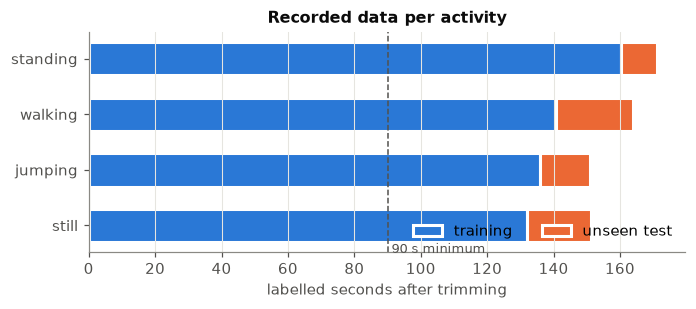

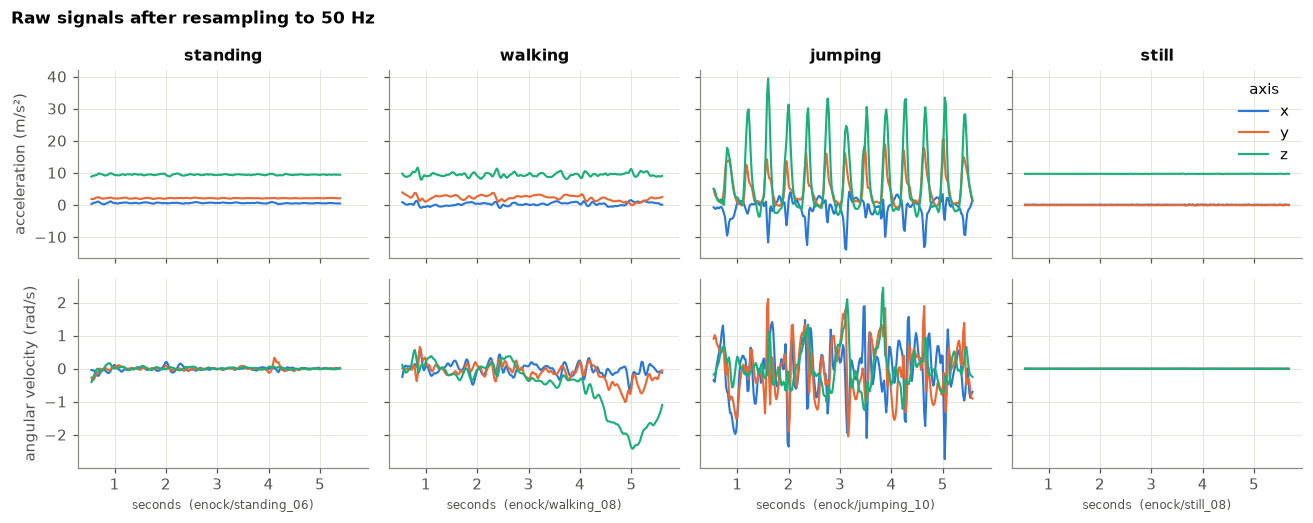

In [6]:
# Figure: how much labelled data each activity has
fig, ax = plt.subplots(figsize=(7, 2.6))
y = np.arange(K)
ax.barh(y, seconds.train, color=BLUE, height=0.6, edgecolor=SURFACE, linewidth=2, label="training")
ax.barh(y, seconds.test, left=seconds.train, color=ORANGE, height=0.6, edgecolor=SURFACE, linewidth=2, label="unseen test")
ax.axvline(90, color=INK_2, lw=1, ls="--")
ax.text(90, K - 0.45, " 90 s minimum", color=INK_2, fontsize=8.5, va="bottom")
ax.set_yticks(y, ACTIVITIES); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("labelled seconds after trimming"); ax.set_title("Recorded data per activity")
ax.legend(loc="lower right", ncol=2)
save(fig, "data_seconds_per_activity")

# Figure: one typical training clip per activity (acc and gyro, after harmonisation)
fig, axes = plt.subplots(2, K, figsize=(12, 4.8), sharex=True, sharey="row")
for j, act in enumerate(ACTIVITIES):
    cand = [r for r in recordings if r["activity"] == act and r["split"] == "train"]
    for ax in axes[:, j]:
        ax.set_title(act if ax is axes[0, j] else "")
    if not cand:
        continue
    r = sorted(cand, key=lambda r: len(r["data"]))[len(cand) // 2]
    d = r["data"]
    for axis in "xyz":
        axes[0, j].plot(d.seconds_elapsed, d[f"acc_{axis}"], color=AXIS_COLORS[axis], label=axis)
        axes[1, j].plot(d.seconds_elapsed, d[f"gyro_{axis}"], color=AXIS_COLORS[axis], label=axis)
    axes[1, j].set_xlabel(f"seconds  ({r['member']}/{r['recording']})", fontsize=8)
axes[0, 0].set_ylabel("acceleration (m/s²)"); axes[1, 0].set_ylabel("angular velocity (rad/s)")
axes[0, -1].legend(title="axis", loc="upper right")
fig.suptitle(f"Raw signals after resampling to {TARGET_HZ} Hz", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "raw_signals_by_activity")

## 2. Windowing and feature extraction

**Window size.** Each window is 2.0 s (100 samples at 50 Hz) and windows advance by 1.0 s. A normal walking step takes about 0.5 s and continuous jumping repeats every 0.4 to 0.6 s, so a 2 s window always holds at least three full movement cycles; that makes the variance and spectral features stable from one window to the next. The FFT of a 2 s window has a true frequency resolution of 1/2 s = 0.5 Hz, enough to separate the 0 Hz of a resting phone from the roughly 2 Hz rhythm of walking or jumping. Shorter windows (1 s) would give 1 Hz resolution and only one or two cycles; longer windows (4 s) would leave only one to three windows in a 5 to 10 s clip and blur the moment an activity changes. Because the window is defined in seconds and every recording is first resampled to 50 Hz, the window covers the same span of motion on every phone.

**Features** (computed on the acceleration magnitude |a| and gyroscope magnitude |ω|, which do not depend on how the phone is rotated in the hand, except tilt, which measures exactly that):

| Feature | Domain | Why it separates the activities |
|---|---|---|
| `log_acc_std`: std of \|a\| | time | Movement intensity. Near zero for a phone on a table, small for standing sway, larger for walking, largest for jumping. |
| `log_acc_range`: max − min of \|a\| | time | Jumping has a free-fall phase (\|a\| near 0) and hard landings (3–4 g); walking never does, so the range separates the two even when their rhythm is similar. |
| `log_gyro_mean`: mean \|ω\| | time | Rotation. A phone on a table does not rotate at all, a hand-held phone always sways a little; this is the clearest cue between *still* and *standing*. |
| `tilt_deg`: angle between gravity and the screen normal | time | Orientation. Flat on the table gives about 0°, upright in the hand about 70–90°. |
| `dom_freq`: frequency of the largest FFT peak (0.3–12 Hz) | frequency | The cadence of the movement: around 1.6–2.2 Hz for walking and jumping, no stable peak for the static activities. |
| `spec_centroid`: power-weighted mean frequency | frequency | Landing impacts spread energy into higher harmonics, so jumping has a higher centroid than walking. |
| `spec_entropy`: normalised entropy of the power spectrum | frequency | Periodic motion concentrates power in a few peaks (low entropy); sensor noise on a resting phone is spread evenly (high entropy). |

The three magnitude features are log10-transformed because they span several orders of magnitude between a resting and a jumping phone; on the log scale each class is closer to the bell shape that a Gaussian emission assumes. The FFT uses a Hann window to limit spectral leakage and is zero-padded to 4× the window length to place the peak more precisely (the true resolution is still 0.5 Hz).

**Normalisation.** Features have different units (degrees, Hz, log m/s²). They are z-scored with the mean and standard deviation of the *training* windows only, and those same statistics are applied to the test windows, so nothing about the test data leaks into training. Z-scoring suits a Gaussian model better than min–max scaling: it keeps the shape of each distribution, and one unusually hard landing does not squash every other value into a narrow band.

In [7]:
WIN, STEP = int(round(WINDOW_S * TARGET_HZ)), int(round(STEP_S * TARGET_HZ))
NFFT  = 4 * WIN
FREQS = np.fft.rfftfreq(NFFT, d=1.0 / TARGET_HZ)
BAND  = (FREQS >= 0.3) & (FREQS <= 12.0)
HANN  = np.hanning(WIN)

FEATURE_INFO = {
    "log_acc_std":   "log10 std of |acc| (m/s²)",
    "log_acc_range": "log10 range of |acc| (m/s²)",
    "log_gyro_mean": "log10 mean |gyro| (rad/s)",
    "tilt_deg":      "tilt from screen normal (°)",
    "dom_freq":      "dominant frequency (Hz)",
    "spec_centroid": "spectral centroid (Hz)",
    "spec_entropy":  "spectral entropy (0–1)",
}

def window_features(seg):
    """Seven features for one window of shape (WIN, 6): acc x/y/z then gyro x/y/z."""
    acc, gyr = seg[:, :3], seg[:, 3:]
    a, g = np.linalg.norm(acc, axis=1), np.linalg.norm(gyr, axis=1)
    grav = acc.mean(axis=0)
    power = np.abs(np.fft.rfft((a - a.mean()) * HANN, n=NFFT))[BAND] ** 2 + 1e-8   # small floor: a perfectly
    f, pn = FREQS[BAND], power / power.sum()                                         # flat signal reads as flat noise
    return {
        "log_acc_std":   np.log10(a.std() + 1e-3),
        "log_acc_range": np.log10(np.ptp(a) + 1e-3),
        "log_gyro_mean": np.log10(g.mean() + 1e-3),
        "tilt_deg":      np.degrees(np.arccos(np.clip(abs(grav[2]) / (np.linalg.norm(grav) + 1e-9), 0, 1))),
        "dom_freq":      f[power.argmax()],
        "spec_centroid": float((f * pn).sum()),
        "spec_entropy":  float(-(pn * np.log2(pn)).sum() / np.log2(len(pn))),
    }

rows = []
for r in recordings:
    df = r["data"]
    X, lab = df[SENSOR_COLS].to_numpy(), df["activity"].to_numpy()
    for i, s in enumerate(range(0, len(df) - WIN + 1, STEP)):
        vals, cnt = np.unique(lab[s:s + WIN], return_counts=True)
        maj = vals[cnt.argmax()]
        label = maj if (maj != "unlabeled" and cnt.max() >= WIN / 2) else None   # majority label, else unlabelled
        rows.append(dict(member=r["member"], recording=r["recording"], split=r["split"], win=i,
                         t_center=df.seconds_elapsed.iat[s + WIN // 2], label=label, **window_features(X[s:s + WIN])))
feat = pd.DataFrame(rows)

FEATURES = list(FEATURE_INFO)
if not qa.gravity_in_acc.all():
    FEATURES.remove("tilt_deg")
    print("Some recordings have no gravity component, so tilt_deg is dropped. "
          "Export TotalAcceleration (or Gravity) from every phone to keep it.")

feat["y"] = feat.label.map({a: i for i, a in enumerate(ACTIVITIES)}).fillna(-1).astype(int)
print(f"{len(feat)} windows of {WIN} samples, step {STEP}; features: {FEATURES}")
display(feat.groupby(["split", "label"]).size().unstack(fill_value=0).reindex(columns=ACTIVITIES, fill_value=0))

528 windows of 100 samples, step 50; features: ['log_acc_std', 'log_acc_range', 'log_gyro_mean', 'tilt_deg', 'dom_freq', 'spec_centroid', 'spec_entropy']


label,standing,walking,jumping,still
split,,,,
test,11,22,16,21
train,123,110,105,104


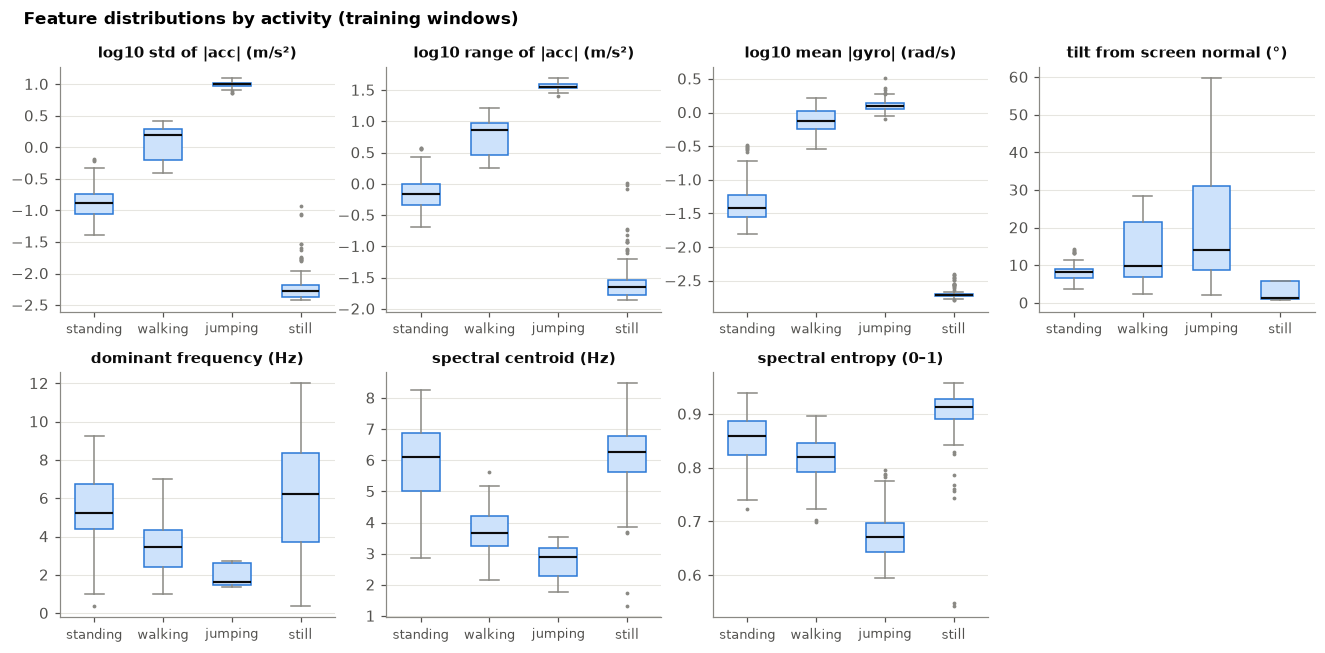

In [8]:
is_train = feat.split == "train"
mu = feat.loc[is_train, FEATURES].mean()
sd = feat.loc[is_train, FEATURES].std(ddof=0).replace(0, 1.0)
feat_z = feat.copy()
feat_z[FEATURES] = (feat[FEATURES] - mu) / sd
pd.DataFrame({"train_mean": mu, "train_std": sd}).to_csv(RES_DIR / "normalisation_stats.csv")
feat.to_csv(RES_DIR / "window_features.csv", index=False)

# Figure: each feature by activity (training windows, original units)
ncol = 4
nrow = int(np.ceil(len(FEATURES) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(12, 3.0 * nrow))
axes = axes.ravel()
tr = feat[is_train & (feat.y >= 0)]
for ax, fname in zip(axes, FEATURES):
    data = [tr.loc[tr.label == a, fname].to_numpy() for a in ACTIVITIES]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55, medianprops=dict(color=INK, lw=1.4),
                    whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                    flierprops=dict(marker="o", markersize=2.5, markerfacecolor=MUTED, markeredgecolor="none"))
    for box in bp["boxes"]:
        box.set(facecolor=BLUE_LIGHT, edgecolor=BLUE, linewidth=1)
    ax.set_xticks(range(1, K + 1), ACTIVITIES, fontsize=8.5)
    ax.set_title(FEATURE_INFO[fname], fontsize=9.5)
    ax.grid(axis="x", visible=False)
for ax in axes[len(FEATURES):]:
    ax.axis("off")
fig.suptitle("Feature distributions by activity (training windows)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "feature_distributions")

## 3. Model components

| Element | In this model |
|---|---|
| Hidden states Z | K = 4 activities: standing, walking, jumping, still. One state per 1 s window step. |
| Observations X | The z-scored feature vector of each window (7 numbers, 6 if tilt is unavailable). |
| Transition probabilities A | A[i, j] = P(z<sub>t</sub> = j \| z<sub>t−1</sub> = i), a 4 × 4 matrix. Because one step is 1 s, the expected time spent in state i before leaving is 1 / (1 − A[i, i]) seconds. |
| Emission probabilities B | b<sub>k</sub>(x) = N(x; μ<sub>k</sub>, Σ<sub>k</sub>), one multivariate Gaussian per activity (diagonal Σ by default; with only a few hundred windows a full 7 × 7 covariance per state is easy to over-fit). |
| Initial probabilities π | π<sub>k</sub> = P(z<sub>1</sub> = k), the activity a recording starts in. |

## 4. Algorithms and why they fit this task

* **Forward algorithm** gives P(X \| model) summed over every possible state path. It is used to track training progress and is the building block of Baum–Welch.
* **Baum–Welch (EM)** re-estimates A, B and π from the forward–backward posteriors and is guaranteed not to decrease the likelihood. It is initialised from a supervised estimate (class means and variances of the labelled windows, transition counts from consecutive labels), which fixes which hidden state means which activity. EM maximises likelihood, not accuracy, so section 5 checks on the test data whether it helps or hurts sensitivity and specificity compared with the supervised estimate.
* **Viterbi** returns the single most probable sequence of activities. Because it scores whole paths, a window whose features are ambiguous is pulled towards the activity of its neighbours, which removes one-window flickers and raises accuracy on continuous recordings. It is the decoder behind the evaluation table. Posterior decoding (most probable state for each window separately) is reported next to it for comparison.

All recursions run in log space, so long recordings never underflow. The next cell implements the model; the cell after it checks the forward, backward and Viterbi code against brute-force enumeration of every state path on small random models.

In [9]:
def logsumexp(a, axis=None):
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    s = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
    return s.item() if axis is None else np.squeeze(s, axis=axis)


class GaussianHMM:
    """Hidden Markov Model with Gaussian emissions, numpy only.

    pi     (K,)                 initial state probabilities
    A      (K, K)               A[i, j] = P(z_t = j | z_{t-1} = i)
    means  (K, D)               emission means
    covars (K, D) or (K, D, D)  emission covariances ("diag" or "full")
    """

    def __init__(self, n_states, cov_type="diag", min_var=1e-3, pseudo_count=1.0):
        self.K, self.cov_type = n_states, cov_type
        self.min_var = min_var        # variance floor; stops a state collapsing onto a few identical windows
        self.pseudo = pseudo_count    # Dirichlet pseudo-count on A and pi; keeps unseen transitions possible
        self.history, self.converged, self.n_iter = [], False, 0

    # ---- emission model -----------------------------------------------------
    def log_emission(self, X):
        """log N(x_t | mean_k, cov_k) for every window t and state k -> (T, K)."""
        T, D = X.shape
        out = np.empty((T, self.K))
        for k in range(self.K):
            diff = X - self.means[k]
            if self.cov_type == "diag":
                var = self.covars[k]
                out[:, k] = -0.5 * (D * np.log(2 * np.pi) + np.log(var).sum() + (diff ** 2 / var).sum(axis=1))
            else:
                L = np.linalg.cholesky(self.covars[k])
                sol = np.linalg.solve(L, diff.T)
                out[:, k] = -0.5 * (D * np.log(2 * np.pi) + 2 * np.log(np.diag(L)).sum() + (sol ** 2).sum(axis=0))
        return out

    # ---- forward / backward ---------------------------------------------------
    def _forward(self, logB):
        logA = np.log(self.A)
        la = np.empty_like(logB)
        la[0] = np.log(self.pi) + logB[0]
        for t in range(1, len(logB)):
            la[t] = logsumexp(la[t - 1][:, None] + logA, axis=0) + logB[t]
        return la, logsumexp(la[-1])

    def _backward(self, logB):
        logA = np.log(self.A)
        lb = np.zeros_like(logB)
        for t in range(len(logB) - 2, -1, -1):
            lb[t] = logsumexp(logA + (logB[t + 1] + lb[t + 1])[None, :], axis=1)
        return lb

    def score(self, X):
        """log P(X | model) via the forward algorithm."""
        return self._forward(self.log_emission(X))[1]

    def posteriors(self, X):
        """gamma[t, k] = P(z_t = k | X); xi_sum[i, j] = sum_t P(z_t = i, z_t+1 = j | X); log-likelihood."""
        logB = self.log_emission(X)
        la, ll = self._forward(logB)
        lb = self._backward(logB)
        gamma = np.exp(la + lb - ll)
        if len(X) > 1:
            log_xi = la[:-1, :, None] + np.log(self.A)[None] + (logB[1:] + lb[1:])[:, None, :] - ll
            xi_sum = np.exp(log_xi).sum(axis=0)
        else:
            xi_sum = np.zeros((self.K, self.K))
        return gamma, xi_sum, ll

    # ---- decoding -----------------------------------------------------------------
    def viterbi(self, X):
        """Most probable state path and its log-probability."""
        logB, logA = self.log_emission(X), np.log(self.A)
        T = len(X)
        delta = np.log(self.pi) + logB[0]
        back = np.zeros((T, self.K), dtype=int)
        for t in range(1, T):
            scores = delta[:, None] + logA          # scores[i, j]: best path ending in i, then i -> j
            back[t] = scores.argmax(axis=0)
            delta = scores.max(axis=0) + logB[t]
        path = np.empty(T, dtype=int)
        path[-1] = delta.argmax()
        for t in range(T - 1, 0, -1):
            path[t - 1] = back[t, path[t]]
        return path, float(delta.max())

    def posterior_decode(self, X):
        return self.posteriors(X)[0].argmax(axis=1)

    def emission_decode(self, X):
        """Ignore time: pick the state whose Gaussian best explains each window on its own."""
        return self.log_emission(X).argmax(axis=1)

    # ---- estimation -----------------------------------------------------------------
    def _set_emissions(self, X, W):
        """Weighted maximum-likelihood means and covariances; W[t, k] is the weight of window t for state k.
        Variances (eigenvalues for full covariances) are clipped at min_var, which is the exact maximiser
        under that constraint, so EM stays monotone."""
        nk = W.sum(axis=0) + 1e-12
        self.means = (W.T @ X) / nk[:, None]
        covs = []
        for k in range(self.K):
            diff = X - self.means[k]
            if self.cov_type == "diag":
                covs.append(np.maximum((W[:, k, None] * diff ** 2).sum(axis=0) / nk[k], self.min_var))
            else:
                S = (W[:, k, None] * diff).T @ diff / nk[k]
                vals, vecs = np.linalg.eigh((S + S.T) / 2)
                covs.append((vecs * np.maximum(vals, self.min_var)) @ vecs.T)
        self.covars = np.stack(covs)

    def init_from_labels(self, seqs, labels):
        """Supervised estimate from labelled windows (label -1 = unlabelled, ignored)."""
        X, y = np.vstack(seqs), np.concatenate(labels)
        m = y >= 0
        missing = set(range(self.K)) - set(y[m])
        if missing:
            raise ValueError(f"no labelled training windows for states {sorted(missing)}")
        self._set_emissions(X[m], np.eye(self.K)[y[m]])
        trans = np.full((self.K, self.K), self.pseudo)
        start = np.full(self.K, self.pseudo)
        for lab in labels:
            if lab[0] >= 0:
                start[lab[0]] += 1
            for a, b in zip(lab[:-1], lab[1:]):
                if a >= 0 and b >= 0:
                    trans[a, b] += 1
        self.A = trans / trans.sum(axis=1, keepdims=True)
        self.pi = start / start.sum()
        return self

    def _log_prior(self):
        return self.pseudo * (np.log(self.A).sum() + np.log(self.pi).sum())

    def fit(self, seqs, max_iter=500, tol=1e-5, verbose=True):
        """Baum-Welch. Stops when the mean log-likelihood per window improves by less than `tol`."""
        X, n = np.vstack(seqs), sum(len(s) for s in seqs)
        self.history, self.converged, prev_obj, prev_avg = [], False, -np.inf, -np.inf
        for it in range(1, max_iter + 1):
            # E-step: expected state occupancies and transitions under the current parameters
            gammas, start, trans, ll = [], np.zeros(self.K), np.zeros((self.K, self.K)), 0.0
            for s in seqs:
                g, xi, l = self.posteriors(s)
                gammas.append(g); start += g[0]; trans += xi; ll += l
            self.history.append(ll)
            obj = ll + self._log_prior()          # the quantity EM with pseudo-counts never decreases
            if obj < prev_obj - 1e-6 * abs(prev_obj):
                warnings.warn(f"objective decreased at iteration {it}: {prev_obj:.4f} -> {obj:.4f}")
            avg = ll / n
            if abs(avg - prev_avg) < tol:
                self.converged = True
                break
            prev_obj, prev_avg = obj, avg
            # M-step
            self.pi = (start + self.pseudo) / (start + self.pseudo).sum()
            self.A = (trans + self.pseudo) / (trans + self.pseudo).sum(axis=1, keepdims=True)
            self._set_emissions(X, np.vstack(gammas))
        self.n_iter = it
        if verbose:
            state = "converged" if self.converged else "stopped at max_iter"
            print(f"Baum-Welch {state} after {it} iterations; log-likelihood {self.history[0]:.1f} -> {self.history[-1]:.1f}")
        return self

    def permute(self, order):
        """Reorder states so new state k is old state order[k]."""
        o = np.asarray(order)
        self.pi, self.A = self.pi[o], self.A[np.ix_(o, o)]
        self.means, self.covars = self.means[o], self.covars[o]
        return self

In [10]:
def brute_force_check(seed, cov_type, K_=3, T=5, D=2):
    """Compare forward, backward and Viterbi with explicit enumeration of all K^T state paths."""
    r = np.random.default_rng(seed)
    m = GaussianHMM(K_, cov_type)
    m.pi, m.A = r.dirichlet(np.ones(K_)), r.dirichlet(np.ones(K_), size=K_)
    m.means = r.normal(size=(K_, D))
    if cov_type == "diag":
        m.covars = r.uniform(0.3, 2.0, size=(K_, D))
    else:
        B = r.normal(size=(K_, D, D))
        m.covars = B @ B.transpose(0, 2, 1) + 0.3 * np.eye(D)
    X = r.normal(size=(T, D))
    logB = m.log_emission(X)
    paths = np.array(list(itertools.product(range(K_), repeat=T)))
    logp = np.log(m.pi[paths[:, 0]]) + logB[0, paths[:, 0]]
    for t in range(1, T):
        logp += np.log(m.A[paths[:, t - 1], paths[:, t]]) + logB[t, paths[:, t]]
    assert np.isclose(m.score(X), logsumexp(logp)), "forward"
    path, lp = m.viterbi(X)
    assert np.array_equal(path, paths[logp.argmax()]) and np.isclose(lp, logp.max()), "viterbi"
    gamma, xi, _ = m.posteriors(X)
    w = np.exp(logp - logsumexp(logp))
    for t in range(T):
        assert np.allclose(gamma[t], np.bincount(paths[:, t], weights=w, minlength=K_)), "gamma"
    xi_bf = np.zeros((K_, K_))
    for t in range(T - 1):
        np.add.at(xi_bf, (paths[:, t], paths[:, t + 1]), w)
    assert np.allclose(xi, xi_bf), "xi"

for seed in range(5):
    for ct in ("diag", "full"):
        brute_force_check(seed, ct)
print("forward, backward (gamma and xi) and Viterbi agree with brute-force enumeration")

forward, backward (gamma and xi) and Viterbi agree with brute-force enumeration


training: 84 sequences, 442 windows | test: 2 sequences, 86 windows
Baum-Welch converged after 4 iterations; log-likelihood -755.5 -> -727.5


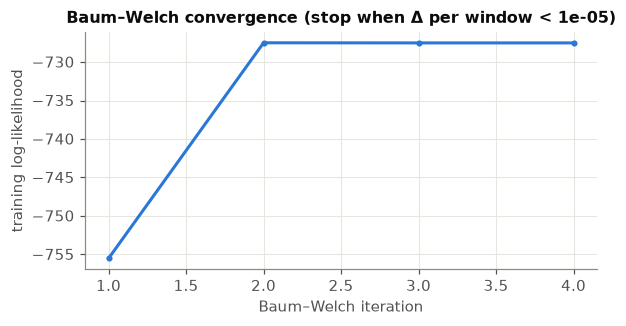

In [11]:
def sequences(split):
    out = []
    for (member, rec), g in feat_z[feat_z.split == split].groupby(["member", "recording"], sort=False):
        g = g.sort_values("win")
        out.append(dict(member=member, recording=rec, X=g[FEATURES].to_numpy(),
                        y=g.y.to_numpy(), t=g.t_center.to_numpy()))
    return out

train, test = sequences("train"), sequences("test")
print(f"training: {len(train)} sequences, {sum(len(s['X']) for s in train)} windows | "
      f"test: {len(test)} sequences, {sum(len(s['X']) for s in test)} windows")

# (a) supervised estimate straight from the labels
hmm_sup = GaussianHMM(K, COV_TYPE).init_from_labels([s["X"] for s in train], [s["y"] for s in train])

# (b) Baum-Welch, started from (a), trained on the training sequences only
hmm_bw = copy.deepcopy(hmm_sup).fit([s["X"] for s in train], tol=BW_TOL)

# EM is unsupervised, so check that state k still means activity k on the training data
def best_state_order(model, seqs):
    y = np.concatenate([s["y"] for s in seqs])
    p = np.concatenate([model.viterbi(s["X"])[0] for s in seqs])
    m = y >= 0
    def acc(order):
        inv = np.argsort(order)
        return (inv[p[m]] == y[m]).mean()
    return max(itertools.permutations(range(model.K)), key=acc)

order = best_state_order(hmm_bw, train)
if list(order) != list(range(K)):
    print("Baum-Welch moved activities to different states; reordering", order)
    hmm_bw.permute(order)

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(range(1, len(hmm_bw.history) + 1), hmm_bw.history, color=BLUE, lw=2, marker="o", markersize=3)
ax.set_xlabel("Baum–Welch iteration"); ax.set_ylabel("training log-likelihood")
ax.set_title(f"Baum–Welch convergence (stop when Δ per window < {BW_TOL:g})")
save(fig, "baum_welch_convergence")

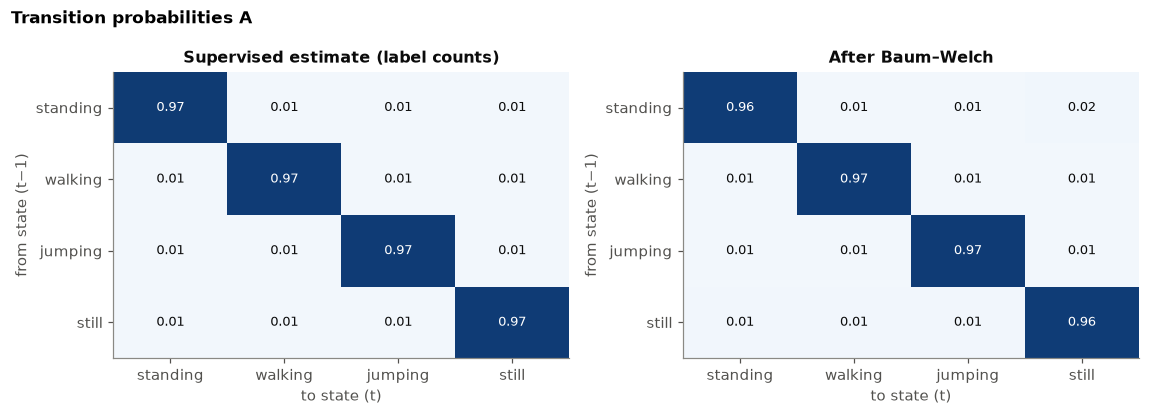

,P(stay),expected stay (s),initial prob
standing,0.962,26.375,0.273
walking,0.968,31.413,0.261
jumping,0.966,29.667,0.239
still,0.965,28.217,0.227


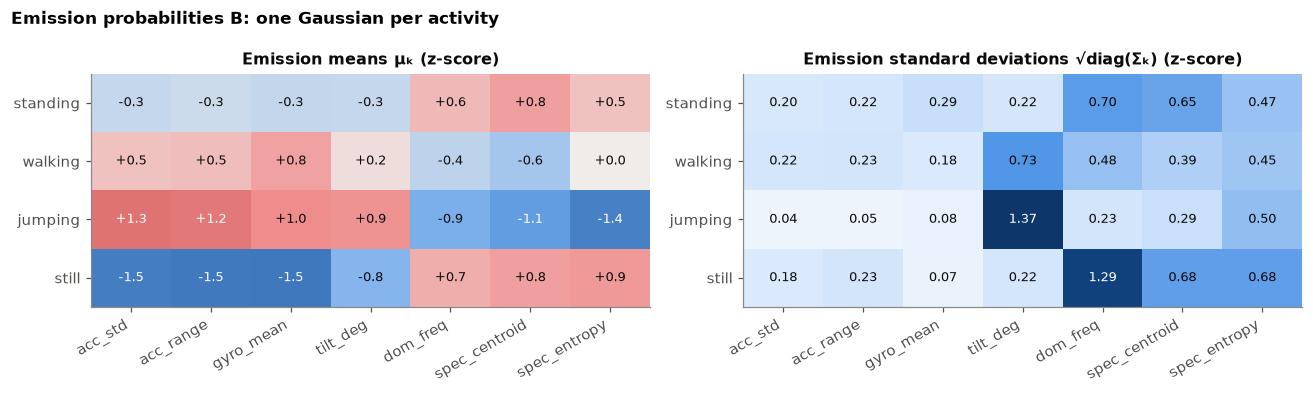

In [12]:
# Transition matrices before and after Baum-Welch
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
for ax, model, title in zip(axes, (hmm_sup, hmm_bw), ("Supervised estimate (label counts)", "After Baum–Welch")):
    heatmap(ax, model.A, ACTIVITIES, ACTIVITIES, SEQ, 0, 1, lambda v: f"{v:.2f}")
    ax.set_xlabel("to state (t)"); ax.set_ylabel("from state (t−1)"); ax.set_title(title)
    ax.set_xticks(range(K), ACTIVITIES, rotation=0, ha="center")
fig.suptitle("Transition probabilities A", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "transition_matrix")

dwell = pd.DataFrame({"P(stay)": np.diag(hmm_bw.A), "expected stay (s)": STEP_S / (1 - np.diag(hmm_bw.A)),
                      "initial prob": hmm_bw.pi}, index=ACTIVITIES).round(3)
display(dwell)

# Emission parameters: what each hidden state expects to see, in z-score units
short = [f.replace("log_", "") for f in FEATURES]
std = np.sqrt(hmm_bw.covars if COV_TYPE == "diag" else np.diagonal(hmm_bw.covars, axis1=1, axis2=2))
lim = np.ceil(np.abs(hmm_bw.means).max())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
heatmap(axes[0], hmm_bw.means, ACTIVITIES, short, DIV, -lim, lim, lambda v: f"{v:+.1f}")
axes[0].set_title("Emission means μₖ (z-score)")
heatmap(axes[1], std, ACTIVITIES, short, SEQ, 0, max(1.0, std.max()), lambda v: f"{v:.2f}")
axes[1].set_title("Emission standard deviations √diag(Σₖ) (z-score)")
fig.suptitle("Emission probabilities B: one Gaussian per activity", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "emission_parameters")
pd.DataFrame(hmm_bw.A, index=ACTIVITIES, columns=ACTIVITIES).to_csv(RES_DIR / "transition_matrix.csv")
pd.DataFrame(hmm_bw.means, index=ACTIVITIES, columns=FEATURES).to_csv(RES_DIR / "emission_means.csv")

## 5. Evaluation on unseen data

The test recordings were never used for training, for Baum–Welch, or for the normalisation statistics. Each one is decoded as a whole sequence with Viterbi; only windows with a label count towards the metrics (windows that fall mostly in an unlabelled transition, such as picking the phone up, are decoded but not scored).

For activity k, treated one-versus-rest: sensitivity = TP / (TP + FN), the share of true *k* windows the model found; specificity = TN / (TN + FP), the share of non-*k* windows it correctly did not call *k*. In the table, the per-activity "Overall Accuracy" is the one-versus-rest accuracy (TP + TN) / N, and the last row gives the usual multi-class accuracy (correct windows / all windows). "Number of Samples" counts 2 s test windows, not raw sensor readings.

In [13]:
def evaluate(y_true, y_pred):
    m = y_true >= 0
    yt, yp = y_true[m], y_pred[m]
    C = np.zeros((K, K), dtype=int)
    np.add.at(C, (yt, yp), 1)
    N, rows = C.sum(), []
    for k in range(K):
        tp, fn = C[k, k], C[k].sum() - C[k, k]
        fp = C[:, k].sum() - tp
        tn = N - tp - fn - fp
        rows.append({"Number of Samples": int(C[k].sum()),
                     "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
                     "Specificity": tn / (tn + fp) if tn + fp else np.nan,
                     "Overall Accuracy": (tp + tn) / N})
    table = pd.DataFrame(rows, index=pd.Index(ACTIVITIES, name="State (Activity)"))
    return C, table, np.trace(C) / N

def run(decoder, seqs):
    return np.concatenate([s["y"] for s in seqs]), np.concatenate([decoder(s["X"]) for s in seqs])

decoders = {
    "Gaussian per window, no transitions":   hmm_sup.emission_decode,
    "HMM supervised estimate + Viterbi":     lambda X: hmm_sup.viterbi(X)[0],
    "HMM Baum-Welch + Viterbi (main model)": lambda X: hmm_bw.viterbi(X)[0],
    "HMM Baum-Welch + posterior decoding":   hmm_bw.posterior_decode,
}
comparison = {}
for name, dec in decoders.items():
    _, tab_tr, acc_tr = evaluate(*run(dec, train))
    C_, tab_te, acc_te = evaluate(*run(dec, test))
    comparison[name] = {"train accuracy": acc_tr, "test accuracy": acc_te,
                        "test mean sensitivity": tab_te.Sensitivity.mean(),
                        "test mean specificity": tab_te.Specificity.mean()}
comparison = pd.DataFrame(comparison).T

C, table, overall = evaluate(*run(decoders["HMM Baum-Welch + Viterbi (main model)"], test))
table.loc["All activities"] = [table["Number of Samples"].sum(), table.Sensitivity.mean(),
                               table.Specificity.mean(), overall]
table["Number of Samples"] = table["Number of Samples"].astype(int)
print("Evaluation table (unseen test data, Baum-Welch + Viterbi). Last row: mean sensitivity, "
      "mean specificity, multi-class accuracy.")
display(table.round(3))
display(comparison.round(3))

per_file = pd.DataFrame([
    {"recording": s["recording"], "member": s["member"], "labelled windows": int((s["y"] >= 0).sum()),
     "accuracy": ((hmm_bw.viterbi(s["X"])[0] == s["y"])[s["y"] >= 0]).mean()}
    for s in test]).set_index("recording")
display(per_file.round(3))

table.to_csv(RES_DIR / "evaluation_table.csv")
comparison.to_csv(RES_DIR / "decoder_comparison.csv")
per_file.to_csv(RES_DIR / "test_accuracy_per_file.csv")
_ = (RES_DIR / "evaluation_table.md").write_text(df_to_markdown(table))

Evaluation table (unseen test data, Baum-Welch + Viterbi). Last row: mean sensitivity, mean specificity, multi-class accuracy.


,Number of Samples,Sensitivity,Specificity,Overall Accuracy
State (Activity),,,,
standing,11,0.727,0.966,0.929
walking,22,1.000,0.896,0.929
jumping,16,0.875,1.000,0.971
still,21,0.905,1.000,0.971
All activities,70,0.877,0.965,0.900


,train accuracy,test accuracy,test mean sensitivity,test mean specificity
"Gaussian per window, no transitions",0.982,0.914,0.889,0.970
HMM supervised estimate + Viterbi,0.986,0.914,0.889,0.970
HMM Baum-Welch + Viterbi (main model),0.986,0.900,0.877,0.965
HMM Baum-Welch + posterior decoding,0.986,0.900,0.877,0.965


,member,labelled windows,accuracy
recording,,,
test_01_enock,enock,36,0.944
test_02_enock,enock,34,0.853


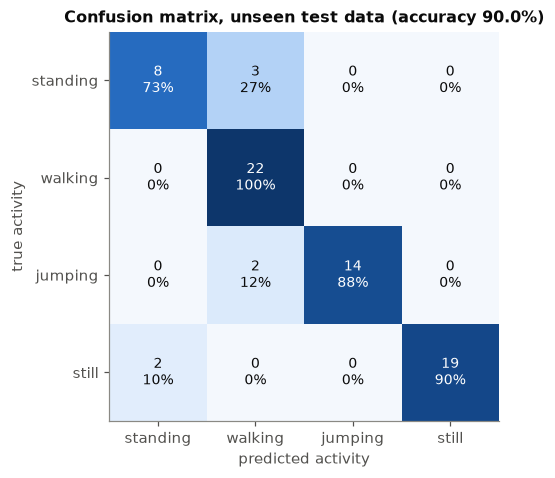

In [14]:
# Confusion matrix on the test windows: counts, coloured by the share of each true activity
row_share = C / np.maximum(C.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.imshow(row_share, cmap=SEQ, vmin=0, vmax=1)
ax.grid(False)
ax.set_xticks(range(K), ACTIVITIES); ax.set_yticks(range(K), ACTIVITIES)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f"{C[i, j]}\n{row_share[i, j]:.0%}", ha="center", va="center", fontsize=9,
                color="white" if row_share[i, j] > 0.55 else INK)
ax.set_xlabel("predicted activity"); ax.set_ylabel("true activity")
ax.set_title(f"Confusion matrix, unseen test data (accuracy {overall:.1%})")
save(fig, "confusion_matrix_test")

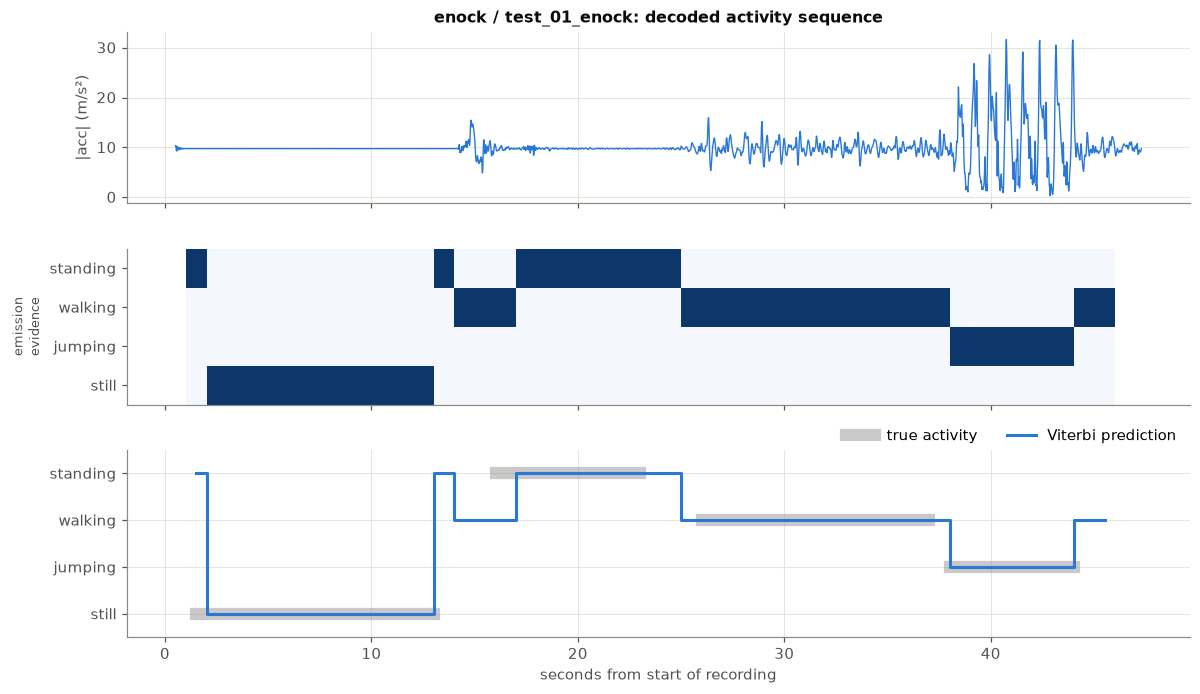

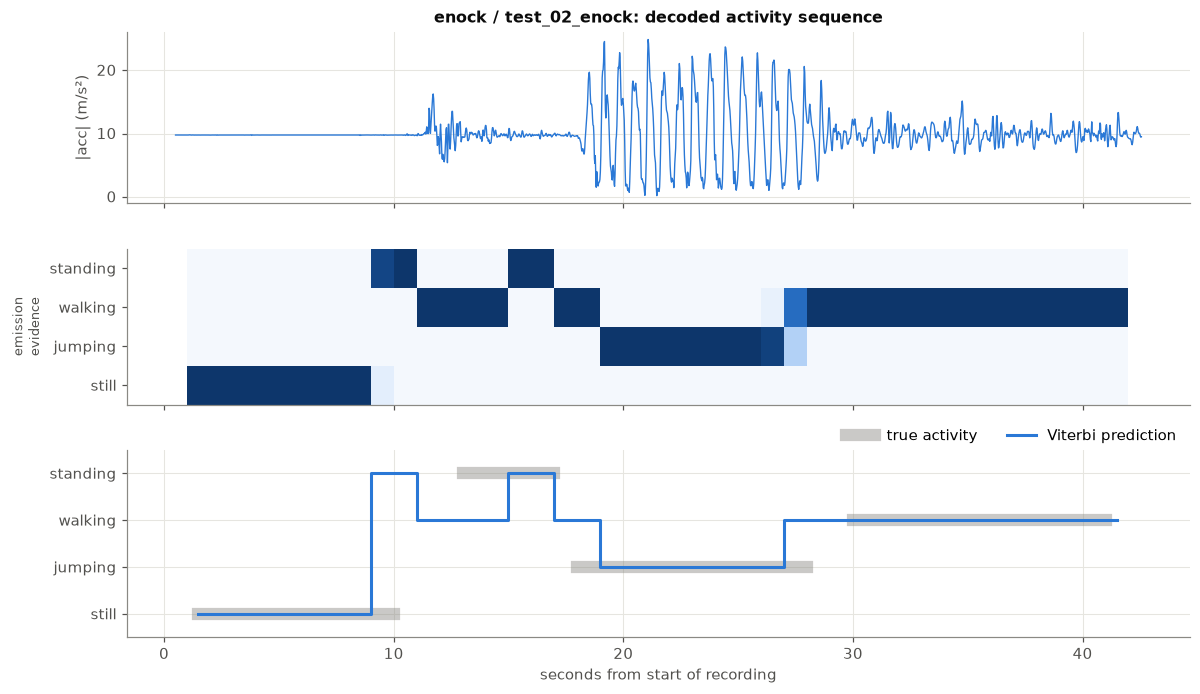

In [15]:
# Decoded test sequences: signal, per-window emission evidence, and true vs Viterbi path
for s in test:
    rec = next(r for r in recordings if r["recording"] == s["recording"] and r["member"] == s["member"])
    d = rec["data"]
    amag = np.linalg.norm(d[["acc_x", "acc_y", "acc_z"]].to_numpy(), axis=1)
    path = hmm_bw.viterbi(s["X"])[0]
    logB = hmm_bw.log_emission(s["X"])
    P = np.exp(logB - logsumexp(logB, axis=1)[:, None])           # evidence from each window alone
    t, h = s["t"], STEP_S / 2

    fig, axes = plt.subplots(3, 1, figsize=(11, 6.4), sharex=True,
                             gridspec_kw=dict(height_ratios=[1.1, 1.0, 1.2]))
    axes[0].plot(d.seconds_elapsed, amag, color=BLUE, lw=0.9)
    axes[0].set_ylabel("|acc| (m/s²)")
    axes[0].set_title(f"{s['member']} / {s['recording']}: decoded activity sequence")
    axes[1].imshow(P.T, aspect="auto", cmap=SEQ, vmin=0, vmax=1, interpolation="nearest",
                   extent=[t[0] - h, t[-1] + h, K - 0.5, -0.5])
    axes[1].grid(False)
    axes[1].set_yticks(range(K), ACTIVITIES)
    axes[1].set_ylabel("emission\nevidence", fontsize=8.5)
    truth = np.where(s["y"] >= 0, s["y"], np.nan).astype(float)
    axes[2].step(t, truth, where="mid", color=MUTED, lw=8, alpha=0.45, label="true activity")
    axes[2].step(t, path, where="mid", color=BLUE, lw=2, label="Viterbi prediction")
    axes[2].set_yticks(range(K), ACTIVITIES)
    axes[2].set_ylim(K - 0.5, -0.5)
    axes[2].set_xlabel("seconds from start of recording")
    axes[2].legend(loc="upper right", ncol=2, bbox_to_anchor=(1, 1.18))
    fig.tight_layout()
    save(fig, f"decoded_{s['member']}_{s['recording']}")

## 6. Numbers for the analysis section

The cell below turns the results into plain statements (easiest and hardest activity, most common confusion, generalisation gap, time constants of the transition matrix). They are facts from this run, meant as raw material for the report's analysis, not as the analysis itself.

In [16]:
sens = table.loc[ACTIVITIES, "Sensitivity"]
off = C.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
main, base = comparison.loc["HMM Baum-Welch + Viterbi (main model)"], comparison.loc["Gaussian per window, no transitions"]
sup = comparison.loc["HMM supervised estimate + Viterbi"]

facts = [
    f"Data: {len(qa)} cleaned recordings from {qa.member.nunique()} members; "
    f"{(qa.split == 'test').sum()} unseen test recordings with {int(table.loc['All activities', 'Number of Samples'])} labelled windows.",
    "Sampling rates (accelerometer, median per member): "
    + ", ".join(f"{m} {r.acc_hz_median:.0f} Hz" for m, r in rates.iterrows()) + f"; all resampled to {TARGET_HZ} Hz.",
    f"Easiest activity on the test data: {sens.idxmax()} (sensitivity {sens.max():.2f}); "
    f"hardest: {sens.idxmin()} (sensitivity {sens.min():.2f}).",
    (f"Most frequent error: true {ACTIVITIES[i]} predicted as {ACTIVITIES[j]} ({off[i, j]} windows, "
     f"{off[i, j] / max(C[i].sum(), 1):.0%} of {ACTIVITIES[i]})." if off.max() > 0 else "No test window was misclassified."),
    f"Accuracy: train {main['train accuracy']:.3f}, test {main['test accuracy']:.3f} "
    f"(gap {main['train accuracy'] - main['test accuracy']:+.3f}).",
    f"Adding transitions (Viterbi) vs classifying each window alone: test accuracy {base['test accuracy']:.3f} -> "
    f"{main['test accuracy']:.3f}.",
    f"Baum-Welch vs supervised estimate (both Viterbi): test accuracy {sup['test accuracy']:.3f} -> "
    f"{main['test accuracy']:.3f}; Baum-Welch {'converged' if hmm_bw.converged else 'did not converge'} "
    f"in {hmm_bw.n_iter} iterations.",
    "Expected time in each state before switching: "
    + ", ".join(f"{a} {v:.1f} s" for a, v in dwell["expected stay (s)"].items()) + ".",
]
order_off = [(ACTIVITIES[a], ACTIVITIES[b], hmm_bw.A[a, b]) for a in range(K) for b in range(K) if a != b]
top = sorted(order_off, key=lambda x: -x[2])[:3]
facts.append("Most likely switches: " + "; ".join(f"{a} -> {b} {p:.3f}" for a, b, p in top) + ".")
for f in facts:
    print("-", f)

summary = {
    "n_recordings": int(len(qa)), "n_members": int(qa.member.nunique()), "target_hz": TARGET_HZ,
    "window_s": WINDOW_S, "step_s": STEP_S, "features": FEATURES, "cov_type": COV_TYPE,
    "bw_iterations": int(hmm_bw.n_iter), "bw_converged": bool(hmm_bw.converged),
    "test_accuracy": float(overall), "facts": facts,
}
(RES_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
print(f"\nFigures in {FIG_DIR}/, tables in {RES_DIR}/")

- Data: 86 cleaned recordings from 1 members; 2 unseen test recordings with 70 labelled windows.
- Sampling rates (accelerometer, median per member): enock 100 Hz; all resampled to 50 Hz.
- Easiest activity on the test data: walking (sensitivity 1.00); hardest: standing (sensitivity 0.73).
- Most frequent error: true standing predicted as walking (3 windows, 27% of standing).
- Accuracy: train 0.986, test 0.900 (gap +0.086).
- Adding transitions (Viterbi) vs classifying each window alone: test accuracy 0.914 -> 0.900.
- Baum-Welch vs supervised estimate (both Viterbi): test accuracy 0.914 -> 0.900; Baum-Welch converged in 4 iterations.
- Expected time in each state before switching: standing 26.4 s, walking 31.4 s, jumping 29.7 s, still 28.2 s.
- Most likely switches: standing -> still 0.019; still -> standing 0.012; still -> walking 0.012.

Figures in figures/, tables in results/
